# Berry phases and Chern number of gapped graphene

In this tutorial you compute the Berry phases of gapped graphene on loops around a valley. You then compute the Chern number of its lower band from the Berry flux through the whole Brillouin zone. Gapped graphene is the honeycomb model of graphene with a potential that differs on the two sublattices. That potential opens a gap at the valleys $K$ and $K'$ and keeps time reversal. PAOFLOW builds the tight-binding Hamiltonian $H_{\alpha\beta}(\mathbf{R})$ of the model from two parameters, in contrast to the DFT Hamiltonian of the [bands and DOS tutorial](tutorial01.ipynb). Every result therefore has an analytic value to check against before you trust the same calls on a material. The method is {py:meth}`~PAOFLOW.PAOFLOW.PAOFLOW.berry_phase`. It needs no k-mesh, because it diagonalises the Hamiltonian on the points of each loop.

**What you will compute**

- The gap that a sublattice potential opens at the valleys of graphene
- The Berry phase of a band on a closed loop in k-space, from the overlaps of its Bloch states
- How the Berry curvature of a gapped Dirac cone spreads around the valley, and why the phase on a loop is not an invariant
- The Chern number as the Berry flux through the whole zone, and why it vanishes for gapped graphene

:::{tip}
This page is built on the case [`graphene_berry_phase_model`](https://github.com/marcobn/PAOFLOW/tree/develop/examples/cases/graphene_berry_phase_model): open it in PAOFLOW Studio with *Examples…* → `graphene_berry_phase_model`, or copy it with `paoflow-gen --example graphene_berry_phase_model`. Its `main.py` makes the PAOFLOW calls of this page in order, without the text, the plots and the checks, and runs in about one minute on one core. To change the parameters of the model, or try the same calls on a model of your own, {download}`download this notebook <tutorial06.ipynb>`. The model is built in code, so the notebook downloads no input and has no setup cell. This tutorial assumes the [bands and DOS tutorial](tutorial01.ipynb), and [How to run PAOFLOW on a tight-binding model](../howtos/tight-binding-model.md) for how a model replaces the DFT steps.
:::

## Required input

This tutorial has no DFT input. You pass the model as a dictionary to the `model` argument of `PAOFLOW`, with its parameters in eV. PAOFLOW builds $H_{\alpha\beta}(\mathbf{R})$ from it, in place of the projection steps of the bands and DOS tutorial. [Choosing the model](../howtos/tight-binding-model.md#choosing-the-model) lists the built-in models and their parameters.

## Gapped graphene and its gap at the valleys

You start from spinless graphene, with one orbital per site and a first-neighbour hopping $t = -1$ eV. To it you add an on-site energy $\pm\Delta/2$ on the two sublattices, with $\Delta = -0.2$ eV (the argument `delta` of the `graphene` model). The sublattice potential breaks inversion symmetry and opens a gap $|\Delta|$ at $K$ and $K'$, where the bands of graphene touch. Time reversal is preserved, so the Berry curvature at $-\mathbf{k}$ is opposite to that at $\mathbf{k}$. The two valleys therefore carry opposite fluxes ([Gapped graphene and the valley Berry phase](../theory/berry-topology.md#gapped-graphene-and-the-valley-berry-phase)).

The cell below builds the model and computes its bands along $\Gamma$–$M$–$K$–$\Gamma$. The path is in crystal coordinates of the two in-plane reciprocal vectors $\mathbf{b}_1$ and $\mathbf{b}_2$, with $K = (\tfrac23, \tfrac13)$.

In [1]:
import numpy as np
from PAOFLOW import PAOFLOW

graphene = PAOFLOW.PAOFLOW(
    model={'label': 'graphene', 't': -1.0, 'delta': -0.2}, outputdir='graphene', verbose=False
)
points = {'G': [0.0, 0.0, 0.0], 'M': [0.5, 0.0, 0.0], 'K': [2 / 3, 1 / 3, 0.0]}
graphene.bands(ibrav=4, nk=300, band_path='G-M-K-G', high_sym_points=points)

bands = np.loadtxt('graphene/bands_0.dat')[:, 1:]
print(f'gap {bands[:, 1].min() - bands[:, 0].max():.4f} eV')
print(f'between {bands[:, 0].max():.3f} and {bands[:, 1].min():.3f} eV')


────────────────────────────────────────────────────────────────────────────────────
   
           ██████╗  █████╗  ██████╗ ███████╗██╗      ██████╗ ██╗    ██╗
           ██╔══██╗██╔══██╗██╔═══██╗██╔════╝██║     ██╔═══██╗██║    ██║
           ██████╔╝███████║██║   ██║█████╗  ██║     ██║   ██║██║ █╗ ██║
           ██╔═══╝ ██╔══██║██║   ██║██╔══╝  ██║     ██║   ██║██║███╗██║
           ██║     ██║  ██║╚██████╔╝██║     ███████╗╚██████╔╝╚███╔███╔╝
           ╚═╝     ╚═╝  ╚═╝ ╚═════╝ ╚═╝     ╚══════╝ ╚═════╝  ╚══╝╚══╝
           
────────────────────────────────────────────────────────────────────────────────────
   From DFT wavefunctions to materials properties via atomic-orbital Hamiltonians   
────────────────────────────────────────────────────────────────────────────────────

Serial execution
Initialization in:                          0.046 sec


Bands in:                                   0.198 sec


gap 0.2000 eV
between -0.100 and 0.100 eV


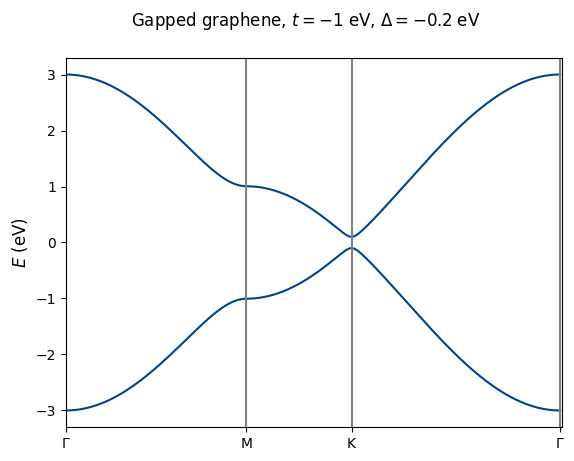

In [2]:
from PAOFLOW import GPAO

GPAO.GPAO().plot_bands(
    'graphene/bands_0.dat',
    sym_points='graphene/kpath_points.txt',
    title=r'Gapped graphene, $t = -1$ eV, $\Delta = -0.2$ eV',
    label=r'$E$ (eV)',
    cols='#004488',
);

The smallest gap between the two bands is 0.200 eV, at $K$, equal to $|\Delta|$. The energy zero lies in the gap, so with one electron per site the lower band is full. Near $K$ the bands form a massive Dirac cone, whose Berry curvature the next section measures.

## Berry phases on loops around a valley

In this section you measure Berry phases on loops around a valley, to find where in the zone the curvature sits. The Berry phase $\gamma$ of a band on a closed loop in k-space is the phase its cell-periodic Bloch states $|u_{n\mathbf{k}}\rangle$ acquire when carried around the loop ([Berry connection and Berry phase](../theory/berry-topology.md#berry-connection-and-berry-phase)). By Stokes' theorem, $\gamma$ is the flux of the Berry curvature through the loop, defined modulo $2\pi$.

`berry_phase()` computes $\gamma$ from the overlap matrices $M_{mn}(\mathbf{k}_i, \mathbf{k}_{i+1}) = \langle u_{m\mathbf{k}_i} | u_{n\mathbf{k}_{i+1}} \rangle$ between consecutive points of the loop, for the bands listed in `sub`. It multiplies them around the loop and returns $\gamma = -\arg \det \prod_i M(\mathbf{k}_i, \mathbf{k}_{i+1})$ ([The discrete Berry phase on a loop](../theory/berry-topology.md#the-discrete-berry-phase-on-a-loop)). The determinant makes $\gamma$ independent of the arbitrary phase of each eigenvector. With several bands in `sub`, it also makes $\gamma$ independent of how the bands mix.

The overlaps use the orbital coefficients of the eigenvectors alone. The textbook overlap also carries the phase $e^{-i(\mathbf{k}_{i+1} - \mathbf{k}_i)\cdot\boldsymbol{\tau}_\alpha}$, set by the positions $\boldsymbol{\tau}_\alpha$ of the orbitals in the cell. Leaving that phase out does not change Chern numbers. It does add a term of the orbital positions to the phase on a loop inside the zone, and on each plaquette below. On a circle centred on an isotropic valley, that term vanishes to leading order ([Overlaps of the orbital coefficients](../theory/berry-topology.md#overlaps-of-the-orbital-coefficients)).

`kspace_method` chooses one of two shapes of loop ([Loops, plaquettes and Wilson loops](../theory/berry-topology.md#loops-plaquettes-and-wilson-loops)):

| `kspace_method` | Loop | Output |
| --- | --- | --- |
| `'circle'` | `nk1` points on a circle of radius `kradius` around `kcenter`, in crystal coordinates, so an ellipse in Cartesian coordinates; `closed=True` joins the last point to the first | one Berry phase, on the last line of the file |
| `'square'` | the rectangle `kxlim` × `kylim`, divided into `nk1` × `nk2` plaquettes, one loop each | a file of three columns $k_x$, $k_y$, $\gamma$, one row per plaquette, and the plaquette corners in a second file ending in `_kgrid_corners.dat` |

Each plaquette phase is shifted by a multiple of $2\pi$ to be continuous with its neighbour on the grid, instead of being reduced to $(-\pi, \pi]$ on its own. The two choices agree when every plaquette encloses much less than $\pi$. The sum of the plaquette phases is then the flux through the rectangle, free of the $2\pi$ ambiguity of one large loop.

The loops below are centred on $K' = (\tfrac13, \tfrac23)$.

In [3]:
k_prime = [1 / 3, 2 / 3, 0.0]


def circle_phase(fname):
    """The Berry phase on the last line of a 'circle' file."""
    return float(open(fname).read().split('Berry phase:')[1])


for sub, tag in (([0], 'lower'), ([1], 'upper'), ([0, 1], 'both')):
    graphene.berry_phase(
        kspace_method='circle',
        kcenter=k_prime,
        kradius=0.05,
        nk1=51,
        sub=sub,
        closed=True,
        method='berry',
        fname=f'circle_{tag}',
    )
    print(
        f'{tag:>5} band(s), circle of radius 0.05: {circle_phase(f"graphene/circle_{tag}.dat"):+.4f}'
    )

graphene.berry_phase(
    kspace_method='square',
    nk1=51,
    nk2=51,
    kxlim=[k_prime[0] - 0.05, k_prime[0] + 0.05],
    kylim=[k_prime[1] - 0.05, k_prime[1] + 0.05],
    sub=[0],
    method='berry',
    fname='patch_lower',
)
print(f'lower band, square of side 0.1: {np.loadtxt("graphene/patch_lower.dat")[:, 2].sum():+.4f}')

Berry phase in:                             7.316 sec


lower band(s), circle of radius 0.05: -2.0688
Berry phase in:                             0.023 sec


upper band(s), circle of radius 0.05: +2.0688
Berry phase in:                             0.087 sec


 both band(s), circle of radius 0.05: +0.0000


Berry phase in:                            20.689 sec


lower band, square of side 0.1: -2.1786


Around $K'$ the two bands carry opposite phases on the circle, $-2.0688$ and $+2.0688$. Together they give zero, because the two bands span the whole space of the model at each $\mathbf{k}$, and that space has no phase to acquire.

On the square that contains the circle, the lower band gives $-2.1786$. The magnitude is larger than on the circle, because the square encloses more of the curvature. A loop around a gapped valley therefore measures the flux through the loop, not a property of the valley.

To see how much of the flux a loop encloses, repeat the circle for radii from 0.002 to 0.25, for the gapped model and for graphene without the sublattice potential ($\Delta = 0$):

In [4]:
radii = [0.002, 0.005, 0.01, 0.02, 0.03, 0.05, 0.08, 0.12, 0.18, 0.25]
gapless = PAOFLOW.PAOFLOW(
    model={'label': 'graphene', 't': -1.0, 'delta': 0.0}, outputdir='gapless', verbose=False
)
for model in (graphene, gapless):
    for radius in radii:
        model.berry_phase(
            kspace_method='circle',
            kcenter=k_prime,
            kradius=radius,
            nk1=201,
            sub=[0],
            closed=True,
            method='berry',
            fname=f'radius_{radius}',
        )

for name in ('graphene', 'gapless'):
    phases = [circle_phase(f'{name}/radius_{r}.dat') for r in radii]
    print(f'{name:>8}: ' + ' '.join(f'{p:+.3f}' for p in phases))


────────────────────────────────────────────────────────────────────────────────────
   
           ██████╗  █████╗  ██████╗ ███████╗██╗      ██████╗ ██╗    ██╗
           ██╔══██╗██╔══██╗██╔═══██╗██╔════╝██║     ██╔═══██╗██║    ██║
           ██████╔╝███████║██║   ██║█████╗  ██║     ██║   ██║██║ █╗ ██║
           ██╔═══╝ ██╔══██║██║   ██║██╔══╝  ██║     ██║   ██║██║███╗██║
           ██║     ██║  ██║╚██████╔╝██║     ███████╗╚██████╔╝╚███╔███╔╝
           ╚═╝     ╚═╝  ╚═╝ ╚═════╝ ╚═╝     ╚══════╝ ╚═════╝  ╚══╝╚══╝
           
────────────────────────────────────────────────────────────────────────────────────
   From DFT wavefunctions to materials properties via atomic-orbital Hamiltonians   
────────────────────────────────────────────────────────────────────────────────────

Serial execution
Initialization in:                          0.008 sec


Berry phase in:                             0.189 sec


Berry phase in:                             0.135 sec


Berry phase in:                             0.170 sec


Berry phase in:                             0.058 sec


Berry phase in:                             0.054 sec


... (12 outputs left out)

Berry phase in:                             0.095 sec


Berry phase in:                             0.090 sec


Berry phase in:                             0.069 sec


graphene: -0.021 -0.125 -0.419 -1.060 -1.532 -2.070 -2.434 -2.647 -2.784 -2.845
 gapless: -3.142 +3.142 +3.142 +3.142 -3.142 +3.142 -3.142 -3.142 -3.142 +3.142


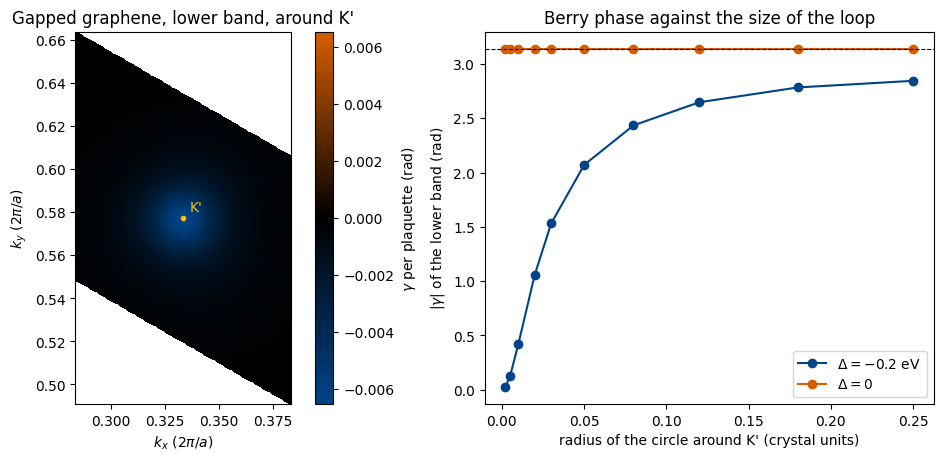

In [5]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

radii = [0.002, 0.005, 0.01, 0.02, 0.03, 0.05, 0.08, 0.12, 0.18, 0.25]
cmap = LinearSegmentedColormap.from_list('palette', ['#004488', '#000000', '#D55E00'])
recip = np.array([[1.0, -1 / np.sqrt(3)], [0.0, 2 / np.sqrt(3)]])  # b1, b2 of the cell (2 pi / a)


def circle_phase(fname):
    return float(open(fname).read().split('Berry phase:')[1])


def square_phases(fname):
    """Plaquette corners (Cartesian) and Berry phase per plaquette of a 'square' run."""
    phase = np.loadtxt(fname)[:, 2]
    n = int(round(np.sqrt(phase.size)))
    corners = np.loadtxt(fname.replace('.dat', '_kgrid_corners.dat'))
    return corners.reshape(n + 1, n + 1, 2, order='F') @ recip, phase.reshape(n, n, order='F')


fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
k, phase = square_phases('graphene/patch_lower.dat')
vmax = np.abs(phase).max()
mesh = left.pcolormesh(k[..., 0], k[..., 1], phase, cmap=cmap, vmin=-vmax, vmax=vmax)
x, y = np.array([1 / 3, 2 / 3]) @ recip
left.plot(x, y, '.', color='#FFC20A', ms=6)
left.annotate("K'", (x, y), xytext=(5, 5), textcoords='offset points', color='#FFC20A')
left.set_aspect('equal')
left.set_title("Gapped graphene, lower band, around K'")
left.set_xlabel(r'$k_x$ ($2\pi/a$)')
left.set_ylabel(r'$k_y$ ($2\pi/a$)')
fig.colorbar(mesh, ax=left, label=r'$\gamma$ per plaquette (rad)')

for name, label, color in (
    ('graphene', r'$\Delta = -0.2$ eV', '#004488'),
    ('gapless', r'$\Delta = 0$', '#D55E00'),
):
    right.plot(
        radii,
        [abs(circle_phase(f'{name}/radius_{r}.dat')) for r in radii],
        'o-',
        color=color,
        label=label,
    )
right.axhline(np.pi, color='#000000', lw=0.8, ls='--')
right.set_xlabel("radius of the circle around K' (crystal units)")
right.set_ylabel(r'$|\gamma|$ of the lower band (rad)')
right.set_title('Berry phase against the size of the loop')
right.legend()
plt.show()

The curvature of the gapped model is spread over a disc around the valley, whereas in graphene without the gap it is concentrated at the Dirac point. The map on the left shows the disc around $K'$. Its phase per plaquette is the flux of the curvature through the plaquette, up to the term of the orbital positions.

The curve on the right measures the same spread with the circles. With the gap, a small loop encloses almost nothing, 0.021 rad at radius 0.002. Half of $\pi$ is reached near radius 0.03, and the largest loop, of radius 0.25, still misses 0.30 rad. Without the gap every loop gives $\pm\pi$, with a sign that is undefined modulo $2\pi$. A smaller gap shrinks the disc. In the limit of no gap the disc collapses onto the Dirac point, which is why the gapless phase is $\pi$ on any loop.

Only the flux through the whole zone, or through a region that holds all the curvature of a valley, is independent of the loop. That flux is what you compute next.

## Chern number: the Berry flux through the whole zone

You now sum the plaquette phases of the lower band over the whole Brillouin zone. The sum gives the Chern number of the band,

$$
C = \frac{1}{2\pi} \sum_\mathrm{plaquettes} \gamma ,
$$

the flux of its Berry curvature through the zone in units of $2\pi$. For a band separated from the others by a gap everywhere in the zone, as here, $C$ is an integer. That holds on any mesh fine enough that every plaquette phase stays well below $\pi$ ([Chern number and the quantised plateau](../theory/berry-topology.md#chern-number-and-the-quantised-plateau)). With `kspace_method='square'`, `kxlim=[0.0, 1.0]` and `kylim=[0.0, 1.0]`, the plaquettes tile one reciprocal cell. The $60 \times 60$ grid of plaquettes takes about half a minute, most of the run of this page.

In [6]:
graphene.berry_phase(
    kspace_method='square',
    nk1=60,
    nk2=60,
    kxlim=[0.0, 1.0],
    kylim=[0.0, 1.0],
    sub=[0],
    method='berry',
    fname='zone_lower',
)

phase = np.loadtxt('graphene/zone_lower.dat')[:, 2]
print(f'lower band: C = {phase.sum() / (2 * np.pi):+.4f}')
print(f'largest plaquette phase {np.abs(phase).max():.3f} rad')

Berry phase in:                            24.742 sec


lower band: C = +0.0000
largest plaquette phase 0.352 rad


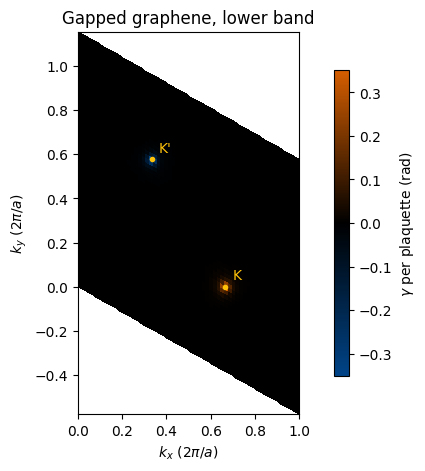

In [7]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

cmap = LinearSegmentedColormap.from_list('palette', ['#004488', '#000000', '#D55E00'])
recip = np.array([[1.0, -1 / np.sqrt(3)], [0.0, 2 / np.sqrt(3)]])  # b1, b2 of the cell (2 pi / a)


def square_phases(fname):
    """Plaquette corners (Cartesian) and Berry phase per plaquette of a 'square' run."""
    phase = np.loadtxt(fname)[:, 2]
    n = int(round(np.sqrt(phase.size)))
    corners = np.loadtxt(fname.replace('.dat', '_kgrid_corners.dat'))
    return corners.reshape(n + 1, n + 1, 2, order='F') @ recip, phase.reshape(n, n, order='F')


k, phase = square_phases('graphene/zone_lower.dat')
fig, ax = plt.subplots(figsize=(6, 4.6), constrained_layout=True)
vmax = np.abs(phase).max()
mesh = ax.pcolormesh(k[..., 0], k[..., 1], phase, cmap=cmap, vmin=-vmax, vmax=vmax)
for name, point in (('K', [2 / 3, 1 / 3]), ("K'", [1 / 3, 2 / 3])):
    x, y = np.array(point) @ recip
    ax.plot(x, y, '.', color='#FFC20A', ms=6)
    ax.annotate(name, (x, y), xytext=(5, 5), textcoords='offset points', color='#FFC20A')
ax.set_aspect('equal')
ax.set_title('Gapped graphene, lower band')
ax.set_xlabel(r'$k_x$ ($2\pi/a$)')
ax.set_ylabel(r'$k_y$ ($2\pi/a$)')
fig.colorbar(mesh, ax=ax, label=r'$\gamma$ per plaquette (rad)', shrink=0.8)
plt.show()

The map covers one reciprocal cell, the parallelogram spanned by $\mathbf{b}_1$ and $\mathbf{b}_2$. The curvature of the lower band sits in discs around $K$ and $K'$ with opposite signs: the disc of the Berry phase loops and its time-reversed partner. The flux through the zone therefore vanishes, and $C = 0$ to machine precision. Gapped graphene is a trivial insulator, whatever the phase on a loop around one valley.

The plaquette phases include the term of the orbital positions from the Berry phase step, but that term integrates to zero over the zone. The largest plaquette phase, 0.352 rad, stays well below $\pi$, which is the condition for the sum to be the flux. If a plaquette came close to $\pi$, you would increase `nk1` and `nk2`.

A nonzero Chern number needs broken time reversal, so that the two valleys carry curvature of the same sign. The Haldane model breaks it with a complex second-neighbour hopping, and has $C = \pm 1$ ([The Haldane model](../theory/berry-topology.md#the-haldane-model)). PAOFLOW builds it from PythTB with the label `haldane_pythtb`, and the calls of this section apply to it unchanged. The Kane–Mele model of the [spin Hall tutorial](tutorial05.ipynb) is two Haldane models with opposite Chern numbers, one per spin, which makes its spin Hall conductivity quantised.

## Where to go next

- [Berry curvature and topological invariants](../theory/berry-topology.md) derives the Berry phase, the curvature and the Chern number used here, works out gapped graphene and the Haldane model, and says where the approximations fail.
- [Spin Hall conductivity of the Kane–Mele model](tutorial05.ipynb) computes the spin Hall conductivity of the Kane–Mele model, a quantum spin Hall insulator.
- [How to compute the non-linear optical response of a tight-binding model](../howtos/nonlinear-optics-model.md) uses the same gapped graphene, whose broken inversion symmetry allows a shift current and second-harmonic generation.
- {py:meth}`~PAOFLOW.PAOFLOW.PAOFLOW.berry_phase` lists all arguments, including the Wilson loops along a path (`kspace_method='path'`) and the Zak phase of one-dimensional systems (`method='zak'`).

In [8]:
# The numbers the tutorial quotes, at the precision it quotes them.
gr = np.loadtxt('graphene/bands_0.dat')[:, 1:]
gap = gr[:, 1].min() - gr[:, 0].max()
assert abs(gap - 0.200) < 1e-3, f'gap of gapped graphene {gap:.4f} eV'

lower = circle_phase('graphene/circle_lower.dat')
assert abs(lower + 2.0688) < 1e-4, f"Berry phase of the lower band around K' {lower:.4f}"
patch = np.loadtxt('graphene/patch_lower.dat')[:, 2].sum()
assert abs(patch + 2.1786) < 1e-4, f'Berry flux of the lower band on the square {patch:.4f}'
radius_003 = abs(circle_phase('graphene/radius_0.03.dat'))
assert abs(radius_003 - 1.53) < 0.01, f'Berry phase on the circle of radius 0.03 {radius_003:.3f}'

chern = np.loadtxt('graphene/zone_lower.dat')[:, 2].sum() / (2 * np.pi)
assert abs(chern) < 1e-4, f'Chern number of gapped graphene {chern:.5f}'